# 05 - Feature Engineering

## Predicting Credit Card Fraud

### Objectives

- Create new features from existing variables.
- Engineer ratios and risk interactions.
- Apply logarithmic transformations.
- Encode cyclical temporal variables.
- Compare original and engineered features.
- Investigate feature importance.
- Perform an ablation study on `is_ai_generated_scam_attempt`.

### Evaluation strategy

- Models: LightGBM and XGBoost.
- Strategies: Baseline and Random Oversampling.
- Stratified train/validation split: 80/20.
- Random state: 42.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import time

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from imblearn.pipeline import Pipeline

from imblearn.over_sampling import RandomOverSampler

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 5)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

In [2]:
possible_paths = [
    Path.cwd() / "data" / "raw",
    Path.cwd().parent / "data" / "raw"
]

DATA_DIR = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError("Could not locate data/raw directory")

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("Train:", train.shape)
print("Test:", test.shape)

Train: (699960, 26)
Test: (299984, 25)


In [3]:
TARGET = "is_fraud"
ID_COL = "id"

X = train.drop(
    columns=[TARGET, ID_COL]
).copy()

y = train[TARGET].astype("int8").copy()

X_test = test.drop(
    columns=[ID_COL]
).copy()

X_test = X_test[X.columns]

print("X:", X.shape)
print("y:", y.shape)
print("X_test:", X_test.shape)

X: (699960, 24)
y: (699960,)
X_test: (299984, 24)


In [4]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)

print(f"Train fraud rate: {y_train.mean() * 100:.4f}%")
print(f"Validation fraud rate: {y_valid.mean() * 100:.4f}%")

Training: (559968, 24)
Validation: (139992, 24)
Train fraud rate: 1.6699%
Validation fraud rate: 1.6701%


In [5]:
def engineer_features(df):

    df = df.copy()

    # -----------------------------------
    # 1. Ratios and activity features
    # -----------------------------------

    df["amount_to_abs_balance_ratio"] = (
        df["amount_usd"] /
        (df["account_balance_usd"].abs() + 1)
    )

    df["cvv_retries_per_recent_txn"] = (
        df["cvv_retry_count"] /
        (df["txn_count_last_24h"] + 1)
    )

    # -----------------------------------
    # 2. Risk flag interactions
    # -----------------------------------

    df["vpn_ip_mismatch"] = (
        df["used_vpn"] &
        df["ip_country_mismatch"]
    )

    df["foreign_ip_mismatch"] = (
        df["is_foreign_transaction"] &
        df["ip_country_mismatch"]
    )

    df["foreign_billing_mismatch"] = (
        df["is_foreign_transaction"] &
        df["billing_shipping_mismatch"]
    )

    # Number of active security risk indicators
    security_flags = [
        "is_foreign_transaction",
        "is_new_merchant",
        "used_vpn",
        "ip_country_mismatch",
        "billing_shipping_mismatch"
    ]

    df["security_risk_flags_count"] = (
        df[security_flags]
        .astype("int8")
        .sum(axis=1)
        .astype("int8")
    )

    # -----------------------------------
    # 3. Numerical interactions
    # -----------------------------------

    df["merchant_velocity_interaction"] = (
        df["merchant_risk_score"] *
        df["velocity_score"]
    )

    df["cvv_velocity_interaction"] = (
        df["cvv_retry_count"] *
        df["velocity_score"]
    )

    # -----------------------------------
    # 4. Logarithmic transformations
    # -----------------------------------

    log_features = [
        "amount_usd",
        "account_balance_usd",
        "cvv_retry_count",
        "prior_disputes"
    ]

    for col in log_features:

        df[f"log_{col}"] = (
            np.sign(df[col]) *
            np.log1p(np.abs(df[col]))
        )

    # -----------------------------------
    # 5. Cyclical time encoding
    # -----------------------------------

    hour = df["time_of_day_hour"] % 24

    day = df["day_of_week"] % 7

    df["hour_sin"] = np.sin(
        2 * np.pi * hour / 24
    )

    df["hour_cos"] = np.cos(
        2 * np.pi * hour / 24
    )

    df["day_sin"] = np.sin(
        2 * np.pi * day / 7
    )

    df["day_cos"] = np.cos(
        2 * np.pi * day / 7
    )

    return df

In [6]:
X_train_fe = engineer_features(X_train)

X_valid_fe = engineer_features(X_valid)

X_test_fe = engineer_features(X_test)

print("Original features:", X_train.shape[1])

print("Engineered training:", X_train_fe.shape)

print("Engineered validation:", X_valid_fe.shape)

print("Engineered test:", X_test_fe.shape)

print(
    "\nNew features:",
    X_train_fe.shape[1] - X_train.shape[1]
)

Original features: 24
Engineered training: (559968, 40)
Engineered validation: (139992, 40)
Engineered test: (299984, 40)

New features: 16


In [7]:
new_features = [
    col for col in X_train_fe.columns
    if col not in X.columns
]

print("New features:")

display(
    X_train_fe[new_features].describe().T
)

New features:


,count,mean,std,min,25%,50%,75%,max
amount_to_abs_balance_ratio,"559,968.00000",0.06676,0.20671,0.00003,0.00878,0.01854,0.03959,14.36529
cvv_retries_per_recent_txn,"559,968.00000",0.02510,0.09642,0.00000,0.00000,0.00000,0.00000,3.00000
security_risk_flags_count,"559,968.00000",0.23263,0.47103,0.00000,0.00000,0.00000,0.00000,5.00000
merchant_velocity_interaction,"559,968.00000",670.15815,480.45147,0.00000,332.21000,593.40000,923.91000,"5,766.39000"
cvv_velocity_interaction,"559,968.00000",1.69032,6.67989,0.00000,0.00000,0.00000,0.00000,145.80000
log_amount_usd,"559,968.00000",3.45637,1.07656,0.69315,2.82197,3.34109,3.78737,8.83546
log_account_balance_usd,"559,968.00000",7.30210,0.72856,4.08177,6.72840,7.23257,7.83123,11.50994
log_cvv_retry_count,"559,968.00000",0.05843,0.19577,0.00000,0.00000,0.00000,0.00000,1.38629
log_prior_disputes,"559,968.00000",0.10354,0.25398,0.00000,0.00000,0.00000,0.00000,1.60944
hour_sin,"559,968.00000",-0.02546,0.70518,-1.00000,-0.70711,0.00000,0.70711,1.00000


In [8]:
numeric_fe = X_train_fe.select_dtypes(
    include=["number"]
)

print(
    "Missing values:",
    X_train_fe.isnull().sum().sum()
)

print(
    "Infinite values:",
    np.isinf(numeric_fe.to_numpy()).sum()
)

assert X_train_fe.isnull().sum().sum() == 0
assert np.isfinite(numeric_fe.to_numpy()).all()

print("Feature Engineering validation successful.")

Missing values: 0
Infinite values: 0
Feature Engineering validation successful.


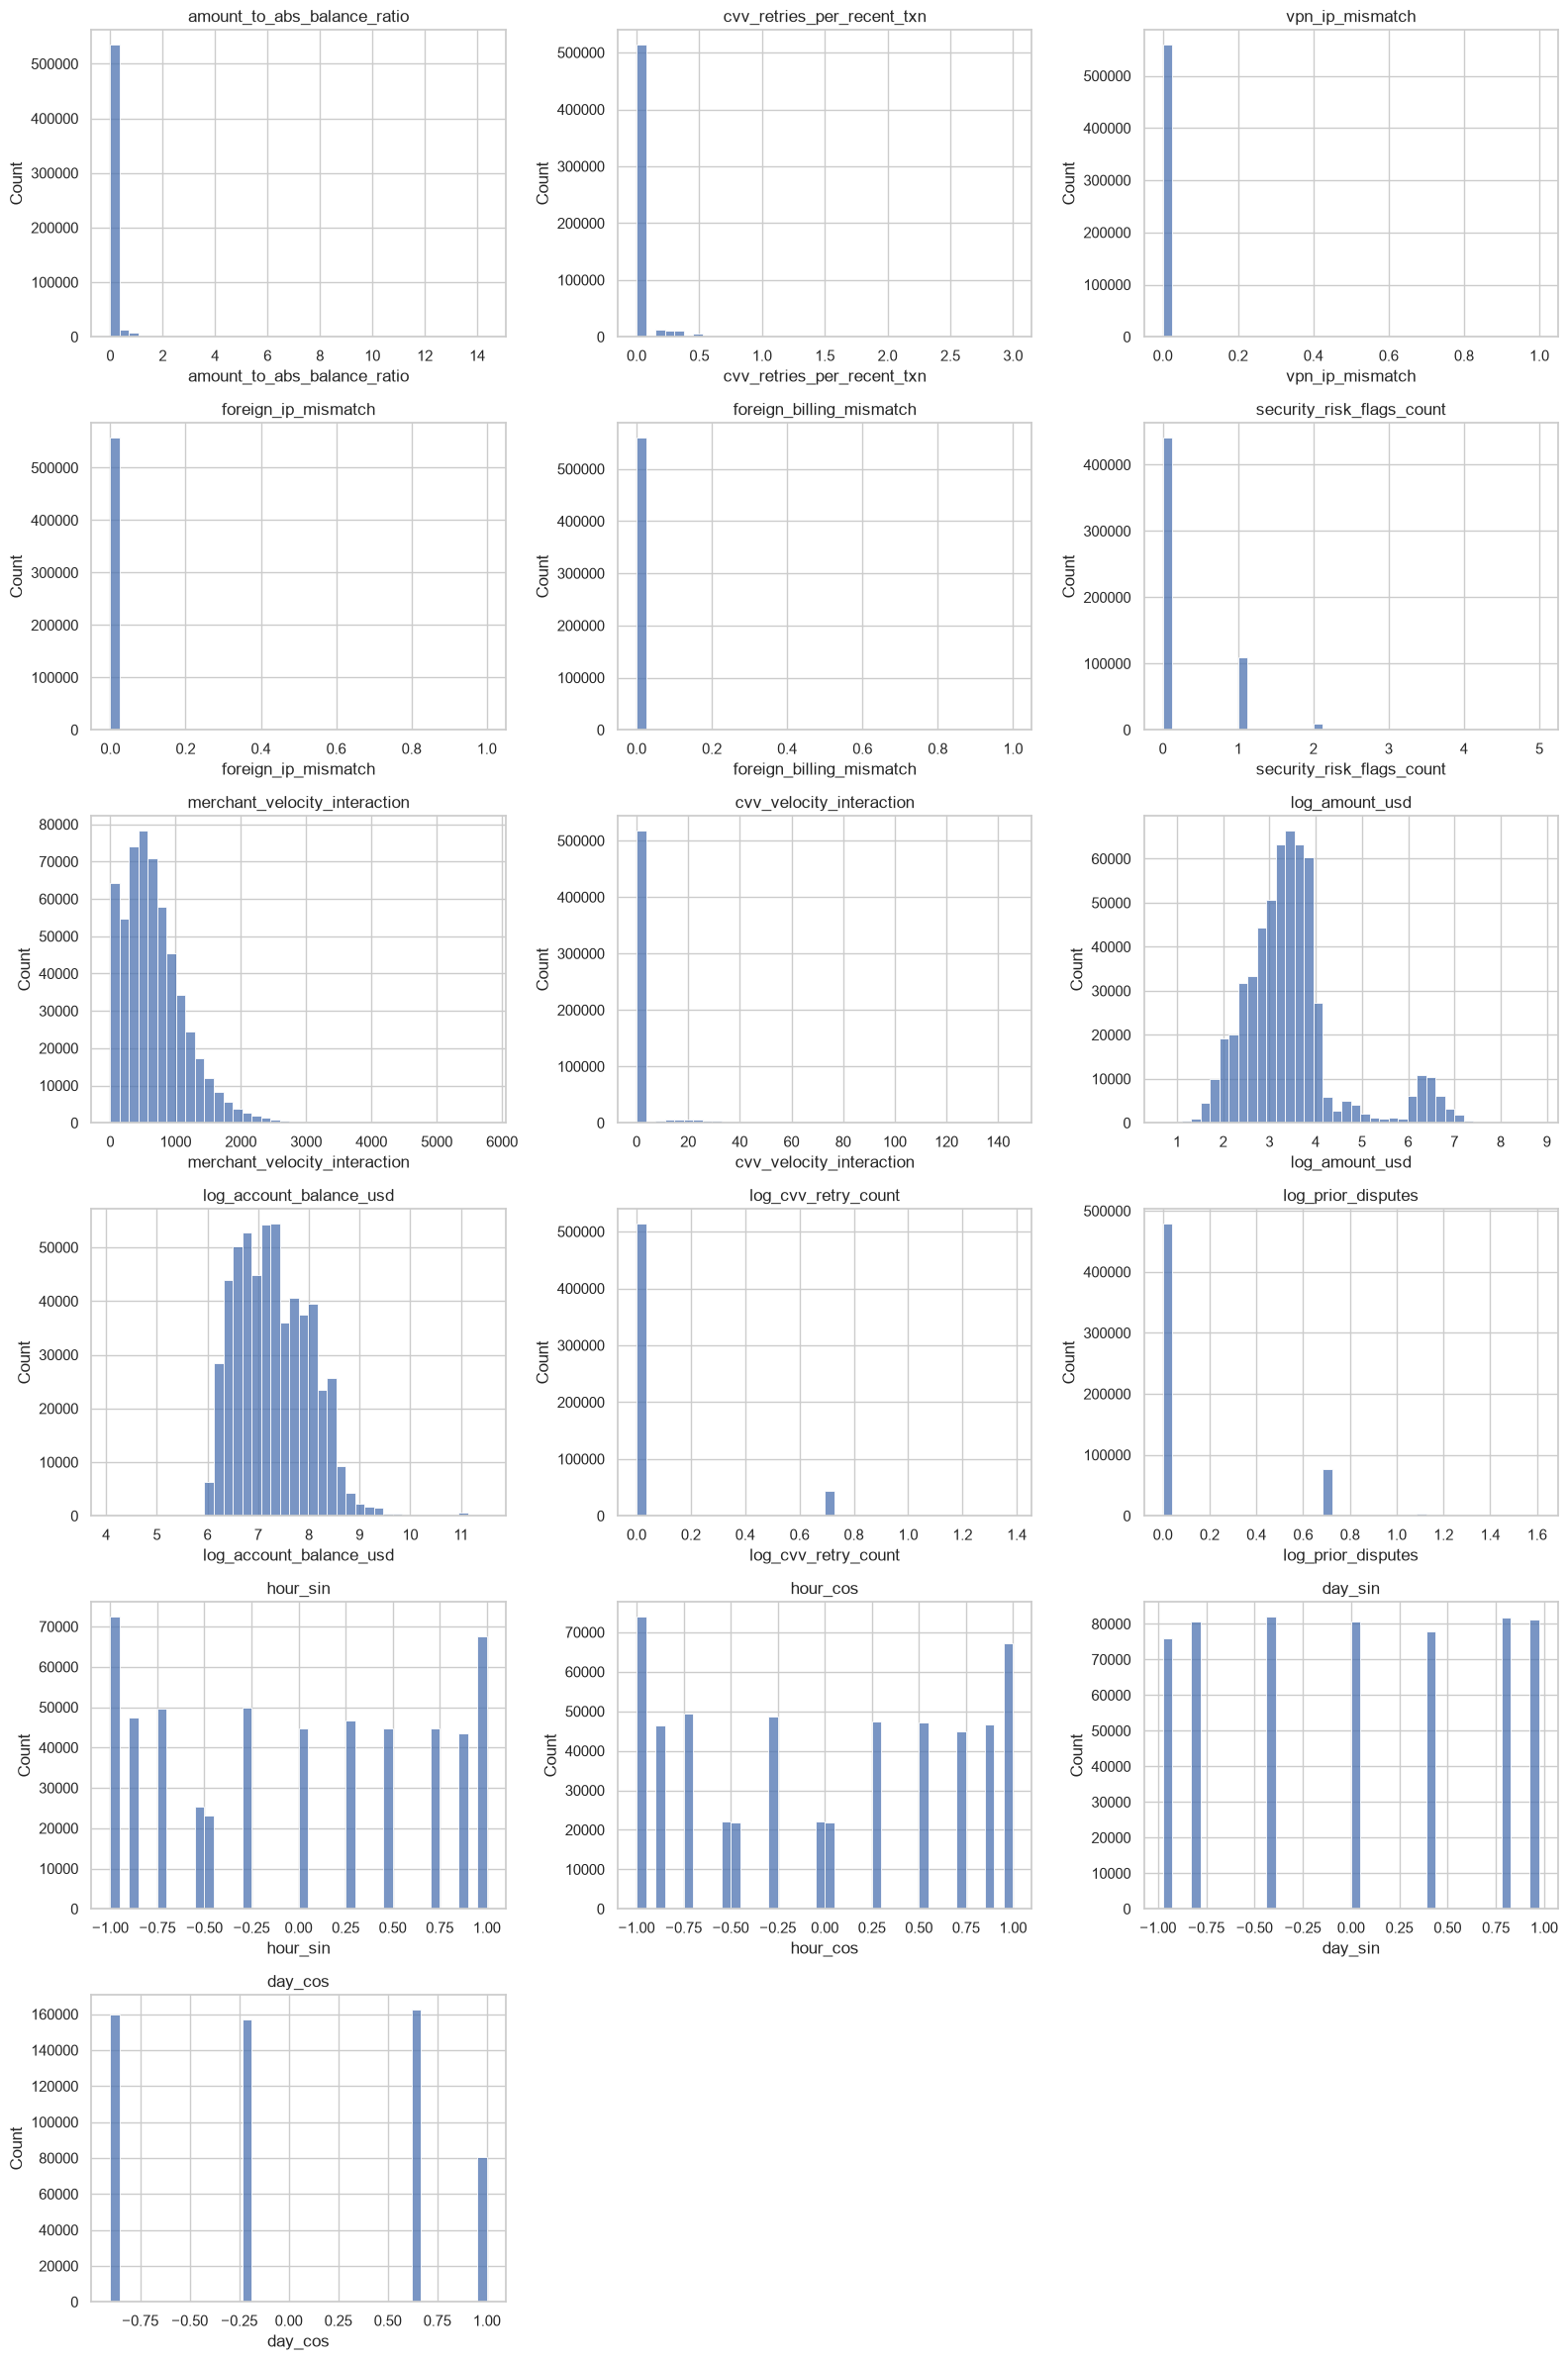

In [9]:
n_cols = 3
n_rows = int(np.ceil(len(new_features) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, n_rows * 4)
)

axes = np.array(axes).flatten()

for i, col in enumerate(new_features):

    sns.histplot(
        data=X_train_fe,
        x=col,
        bins=40,
        ax=axes[i]
    )

    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [10]:
# 1. Original features
X_train_base = X_train.copy()
X_valid_base = X_valid.copy()

# 2. All engineered features
X_train_engineered = X_train_fe.copy()
X_valid_engineered = X_valid_fe.copy()

# 3. Engineered features without AI scam indicator
X_train_no_ai = X_train_fe.drop(
    columns=["is_ai_generated_scam_attempt"]
)

X_valid_no_ai = X_valid_fe.drop(
    columns=["is_ai_generated_scam_attempt"]
)

feature_sets = {

    "Baseline Features": (
        X_train_base,
        X_valid_base
    ),

    "Engineered Features": (
        X_train_engineered,
        X_valid_engineered
    ),

    "Engineered Without AI Flag": (
        X_train_no_ai,
        X_valid_no_ai
    )

}

for name, (X_tr, X_va) in feature_sets.items():

    print(
        f"{name}: "
        f"Train {X_tr.shape} | "
        f"Validation {X_va.shape}"
    )

Baseline Features: Train (559968, 24) | Validation (139992, 24)
Engineered Features: Train (559968, 40) | Validation (139992, 40)
Engineered Without AI Flag: Train (559968, 39) | Validation (139992, 39)


In [11]:
def create_lightgbm():

    return LGBMClassifier(
        objective="binary",
        n_estimators=200,
        learning_rate=0.1,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        n_jobs=-1,
        random_state=42,
        verbosity=-1
    )


def create_xgboost():

    return XGBClassifier(
        objective="binary:logistic",
        eval_metric="auc",
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        tree_method="hist",
        n_jobs=-1,
        random_state=42,
        verbosity=0
    )


model_factories = {
    "LightGBM": create_lightgbm,
    "XGBoost": create_xgboost
}

In [12]:
def create_tree_preprocessor(df):

    bool_cols = [
        col for col in df.columns
        if pd.api.types.is_bool_dtype(df[col])
    ]

    cat_cols = [
        col for col in df.columns
        if (
            pd.api.types.is_object_dtype(df[col])
            or pd.api.types.is_string_dtype(df[col])
            or isinstance(df[col].dtype, pd.CategoricalDtype)
        )
    ]

    num_cols = [
        col for col in df.columns
        if (
            pd.api.types.is_numeric_dtype(df[col])
            and not pd.api.types.is_bool_dtype(df[col])
        )
    ]

    try:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
            dtype=np.float32
        )

    except TypeError:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False,
            dtype=np.float32
        )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", "passthrough", num_cols),
            ("cat", encoder, cat_cols),
            ("bool", "passthrough", bool_cols)
        ],
        remainder="drop"
    )

    return preprocessor

In [13]:
def build_pipeline(estimator, X_reference, strategy):

    steps = []

    # Resampling only during training
    if strategy == "Random Oversampling":

        steps.append((
            "sampler",
            RandomOverSampler(
                sampling_strategy=0.1,
                random_state=42
            )
        ))

    steps.append((
        "preprocessing",
        create_tree_preprocessor(X_reference)
    ))

    steps.append((
        "classifier",
        estimator
    ))

    return Pipeline(steps)

In [14]:
experiment_specs = []

strategies = [
    "Baseline",
    "Random Oversampling"
]

for feature_set_name, (X_tr, X_va) in feature_sets.items():

    for model_name, factory in model_factories.items():

        for strategy in strategies:

            experiment_specs.append({
                "feature_set": feature_set_name,
                "model": model_name,
                "strategy": strategy,
                "estimator": factory()
            })

print("Total experiments:", len(experiment_specs))

Total experiments: 12


In [15]:
fitted_models = {}
valid_probabilities = {}
experiment_results = []

for i, experiment in enumerate(experiment_specs, start=1):

    feature_set_name = experiment["feature_set"]
    model_name = experiment["model"]
    strategy = experiment["strategy"]

    X_tr, X_va = feature_sets[feature_set_name]

    estimator = experiment["estimator"]

    experiment_name = (
        f"{feature_set_name} | "
        f"{strategy} | "
        f"{model_name}"
    )

    print("\n" + "=" * 65)
    print(f"Experiment {i}/{len(experiment_specs)}")
    print(experiment_name)
    print("=" * 65)

    # Build pipeline
    model = build_pipeline(
        estimator,
        X_tr,
        strategy
    )

    # Training
    start_time = time.perf_counter()

    model.fit(X_tr, y_train)

    fit_time = time.perf_counter() - start_time

    # Validation probabilities
    start_time = time.perf_counter()

    y_proba = model.predict_proba(X_va)[:, 1]

    predict_time = time.perf_counter() - start_time

    # Classification threshold
    y_pred = (y_proba >= 0.5).astype("int8")

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_valid,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # Evaluation metrics
    roc_auc = roc_auc_score(y_valid, y_proba)

    avg_precision = average_precision_score(
        y_valid,
        y_proba
    )

    accuracy = accuracy_score(
        y_valid,
        y_pred
    )

    precision = precision_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    # Training distribution after sampling
    if strategy == "Random Oversampling":

        sampler = model.named_steps["sampler"]

        training_rows = len(sampler.sample_indices_)

    else:

        training_rows = len(y_train)

    # Store model and predictions
    fitted_models[experiment_name] = model

    valid_probabilities[experiment_name] = y_proba

    experiment_results.append({

        "experiment": experiment_name,
        "feature_set": feature_set_name,
        "model": model_name,
        "strategy": strategy,

        "roc_auc": roc_auc,
        "average_precision": avg_precision,

        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,

        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "true_negatives": tn,

        "training_rows": training_rows,

        "fit_time_seconds": fit_time,
        "predict_time_seconds": predict_time
    })

    print(f"ROC-AUC: {roc_auc:.5f}")
    print(f"Average Precision: {avg_precision:.5f}")
    print(f"Precision: {precision:.5f}")
    print(f"Recall: {recall:.5f}")
    print(f"F1-Score: {f1:.5f}")
    print(f"Training rows: {training_rows:,}")
    print(f"Fit time: {fit_time:.2f} seconds")

    print("Experiment completed.")


Experiment 1/12
Baseline Features | Baseline | LightGBM
ROC-AUC: 0.94423
Average Precision: 0.50289
Precision: 0.74557
Recall: 0.30582
F1-Score: 0.43373
Training rows: 559,968
Fit time: 1.83 seconds
Experiment completed.

Experiment 2/12
Baseline Features | Random Oversampling | LightGBM
ROC-AUC: 0.94364
Average Precision: 0.50449
Precision: 0.41190
Recall: 0.55090
F1-Score: 0.47136
Training rows: 605,678
Fit time: 2.63 seconds
Experiment completed.

Experiment 3/12
Baseline Features | Baseline | XGBoost
ROC-AUC: 0.94386
Average Precision: 0.50234
Precision: 0.74520
Recall: 0.31523
F1-Score: 0.44304
Training rows: 559,968
Fit time: 3.39 seconds
Experiment completed.

Experiment 4/12
Baseline Features | Random Oversampling | XGBoost
ROC-AUC: 0.94297
Average Precision: 0.50142
Precision: 0.42566
Recall: 0.52652
F1-Score: 0.47075
Training rows: 605,678
Fit time: 4.14 seconds
Experiment completed.

Experiment 5/12
Engineered Features | Baseline | LightGBM
ROC-AUC: 0.94378
Average Precisio

In [16]:
results_df = pd.DataFrame(experiment_results)

results_df = results_df.sort_values(
    "average_precision",
    ascending=False
)

display(results_df)

,experiment,feature_set,model,strategy,roc_auc,average_precision,accuracy,precision,recall,f1_score,true_positives,false_positives,false_negatives,true_negatives,training_rows,fit_time_seconds,predict_time_seconds
5,Engineered Features | Random Oversampling | Li...,Engineered Features,LightGBM,Random Oversampling,0.94333,0.50841,0.97942,0.41262,0.54833,0.47089,1282,1825,1056,135829,605678,3.72124,0.29082
1,Baseline Features | Random Oversampling | Ligh...,Baseline Features,LightGBM,Random Oversampling,0.94364,0.50449,0.97936,0.41190,0.55090,0.47136,1288,1839,1050,135815,605678,2.62591,0.24268
7,Engineered Features | Random Oversampling | XG...,Engineered Features,XGBoost,Random Oversampling,0.94305,0.50396,0.98026,0.42809,0.54106,0.47799,1265,1690,1073,135964,605678,5.29885,0.19294
0,Baseline Features | Baseline | LightGBM,Baseline Features,LightGBM,Baseline,0.94423,0.50289,0.98666,0.74557,0.30582,0.43373,715,244,1623,137410,559968,1.83342,0.25377
2,Baseline Features | Baseline | XGBoost,Baseline Features,XGBoost,Baseline,0.94386,0.50234,0.98676,0.74520,0.31523,0.44304,737,252,1601,137402,559968,3.39111,0.16936
3,Baseline Features | Random Oversampling | XGBoost,Baseline Features,XGBoost,Random Oversampling,0.94297,0.50142,0.98023,0.42566,0.52652,0.47075,1231,1661,1107,135993,605678,4.13737,0.17182
4,Engineered Features | Baseline | LightGBM,Engineered Features,LightGBM,Baseline,0.94378,0.49935,0.98661,0.72498,0.31908,0.44312,746,283,1592,137371,559968,2.19598,0.28997
6,Engineered Features | Baseline | XGBoost,Engineered Features,XGBoost,Baseline,0.94364,0.49872,0.98671,0.73710,0.31779,0.44411,743,265,1595,137389,559968,4.10194,0.18627
11,Engineered Without AI Flag | Random Oversampli...,Engineered Without AI Flag,XGBoost,Random Oversampling,0.94097,0.49522,0.97984,0.41955,0.53978,0.47213,1262,1746,1076,135908,605678,4.96820,0.19532
9,Engineered Without AI Flag | Random Oversampli...,Engineered Without AI Flag,LightGBM,Random Oversampling,0.94163,0.49477,0.97918,0.40740,0.54192,0.46512,1267,1843,1071,135811,605678,3.15832,0.23653


In [17]:
comparison = results_df.pivot_table(
    index=["model", "strategy"],
    columns="feature_set",
    values=[
        "roc_auc",
        "average_precision",
        "recall",
        "f1_score"
    ]
)

display(comparison)

average_precision                      \
feature_set                  Baseline Features Engineered Features   
model    strategy                                                    
LightGBM Baseline                      0.50289             0.49935   
         Random Oversampling           0.50449             0.50841   
XGBoost  Baseline                      0.50234             0.49872   
         Random Oversampling           0.50142             0.50396   

                                                                 f1_score  \
feature_set                  Engineered Without AI Flag Baseline Features   
model    strategy                                                           
LightGBM Baseline                               0.49034           0.43373   
         Random Oversampling                    0.49477           0.47136   
XGBoost  Baseline                               0.48997           0.44304   
         Random Oversampling                    0.49522           0.47075   

                                                                             \
feature_set                  Engineered Features Engineered Without AI Flag   
model    strategy                                                             
LightGBM Baseline                        0.44312                    0.43681   
         Random Oversampling             0.47089                    0.46512   
XGBoost  Baseline                        0.44411                    0.43682   
         Random Oversampling             0.47799                    0.47213   

                                        recall                      \
feature_set                  Baseline Features Engineered Features   
model    strategy                                                    
LightGBM Baseline                      0.30582             0.31908   
         Random Oversampling           0.55090             0.54833   
XGBoost  Baseline                      0.31523             0.31779   
         Random Oversampling           0.52652             0.54106   

                                                                  roc_auc  \
feature_set                  Engineered Without AI Flag Baseline Features   
model    strategy                                                           
LightGBM Baseline                               0.31266           0.94423   
         Random Oversampling                    0.54192           0.94364   
XGBoost  Baseline                               0.31052           0.94386   
         Random Oversampling                    0.53978           0.94297   

                                                                             
feature_set                  Engineered Features Engineered Without AI Flag  
model    strategy                                                            
LightGBM Baseline                        0.94378                    0.94207  
         Random Oversampling             0.94333                    0.94163  
XGBoost  Baseline                        0.94364                    0.94194  
         Random Oversampling             0.94305                    0.94097

In [18]:
ap_comparison = results_df.pivot_table(
    index=["model", "strategy"],
    columns="feature_set",
    values="average_precision"
)

ap_comparison["ap_improvement"] = (
    ap_comparison["Engineered Features"]
    - ap_comparison["Baseline Features"]
)

ap_comparison["ap_improvement_without_ai"] = (
    ap_comparison["Engineered Without AI Flag"]
    - ap_comparison["Baseline Features"]
)

display(
    ap_comparison.sort_values(
        "ap_improvement",
        ascending=False
    )
)

,feature_set,Baseline Features,Engineered Features,Engineered Without AI Flag,ap_improvement,ap_improvement_without_ai
model,strategy,,,,,
LightGBM,Random Oversampling,0.50449,0.50841,0.49477,0.00392,-0.00972
XGBoost,Random Oversampling,0.50142,0.50396,0.49522,0.00254,-0.00620
LightGBM,Baseline,0.50289,0.49935,0.49034,-0.00354,-0.01255
XGBoost,Baseline,0.50234,0.49872,0.48997,-0.00363,-0.01237


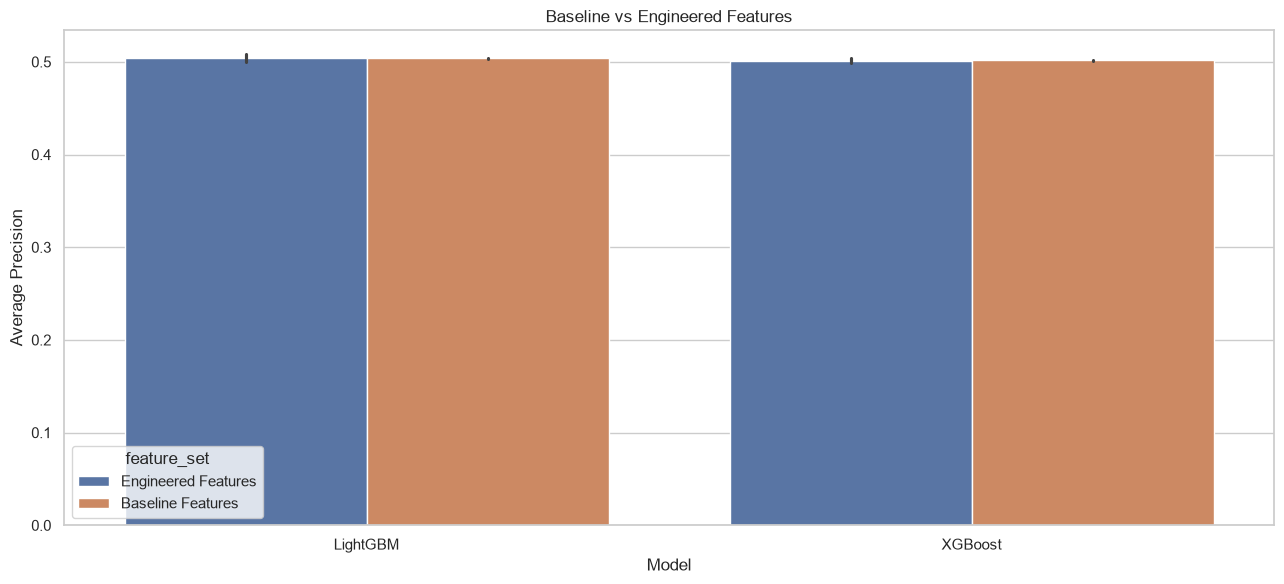

In [19]:
plot_data = results_df[
    results_df["feature_set"].isin([
        "Baseline Features",
        "Engineered Features"
    ])
].copy()

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_data,
    x="model",
    y="average_precision",
    hue="feature_set"
)

plt.title("Baseline vs Engineered Features")
plt.xlabel("Model")
plt.ylabel("Average Precision")

plt.tight_layout()
plt.show()

In [20]:
ai_comparison = results_df[
    results_df["feature_set"].isin([
        "Engineered Features",
        "Engineered Without AI Flag"
    ])
].pivot_table(
    index=["model", "strategy"],
    columns="feature_set",
    values=[
        "roc_auc",
        "average_precision",
        "recall",
        "f1_score"
    ]
)

display(ai_comparison)

average_precision                             \
feature_set                  Engineered Features Engineered Without AI Flag   
model    strategy                                                             
LightGBM Baseline                        0.49935                    0.49034   
         Random Oversampling             0.50841                    0.49477   
XGBoost  Baseline                        0.49872                    0.48997   
         Random Oversampling             0.50396                    0.49522   

                                        f1_score                             \
feature_set                  Engineered Features Engineered Without AI Flag   
model    strategy                                                             
LightGBM Baseline                        0.44312                    0.43681   
         Random Oversampling             0.47089                    0.46512   
XGBoost  Baseline                        0.44411                    0.43682   
         Random Oversampling             0.47799                    0.47213   

                                          recall                             \
feature_set                  Engineered Features Engineered Without AI Flag   
model    strategy                                                             
LightGBM Baseline                        0.31908                    0.31266   
         Random Oversampling             0.54833                    0.54192   
XGBoost  Baseline                        0.31779                    0.31052   
         Random Oversampling             0.54106                    0.53978   

                                         roc_auc                             
feature_set                  Engineered Features Engineered Without AI Flag  
model    strategy                                                            
LightGBM Baseline                        0.94378                    0.94207  
         Random Oversampling             0.94333                    0.94163  
XGBoost  Baseline                        0.94364                    0.94194  
         Random Oversampling             0.94305                    0.94097

In [21]:
best_experiment_name = results_df.iloc[0]["experiment"]

best_model = fitted_models[
    best_experiment_name
]

print("Best experiment:")
print(best_experiment_name)

# Extract classifier and preprocessor
classifier = best_model.named_steps["classifier"]

preprocessor = best_model.named_steps["preprocessing"]

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Get model feature importance
importances = classifier.feature_importances_

feature_importance_df = pd.DataFrame({

    "feature": feature_names,
    "importance": importances

}).sort_values(
    "importance",
    ascending=False
)

display(feature_importance_df.head(20))

Best experiment:
Engineered Features | Random Oversampling | LightGBM


,feature,importance
11,num__merchant_risk_score,567
5,num__customer_age,446
16,num__merchant_velocity_interaction,404
1,num__hours_since_last_txn,402
0,num__amount_usd,377
8,num__velocity_score,376
3,num__distance_from_home_km,313
6,num__account_balance_usd,288
13,num__amount_to_abs_balance_ratio,267
4,num__card_age_months,206


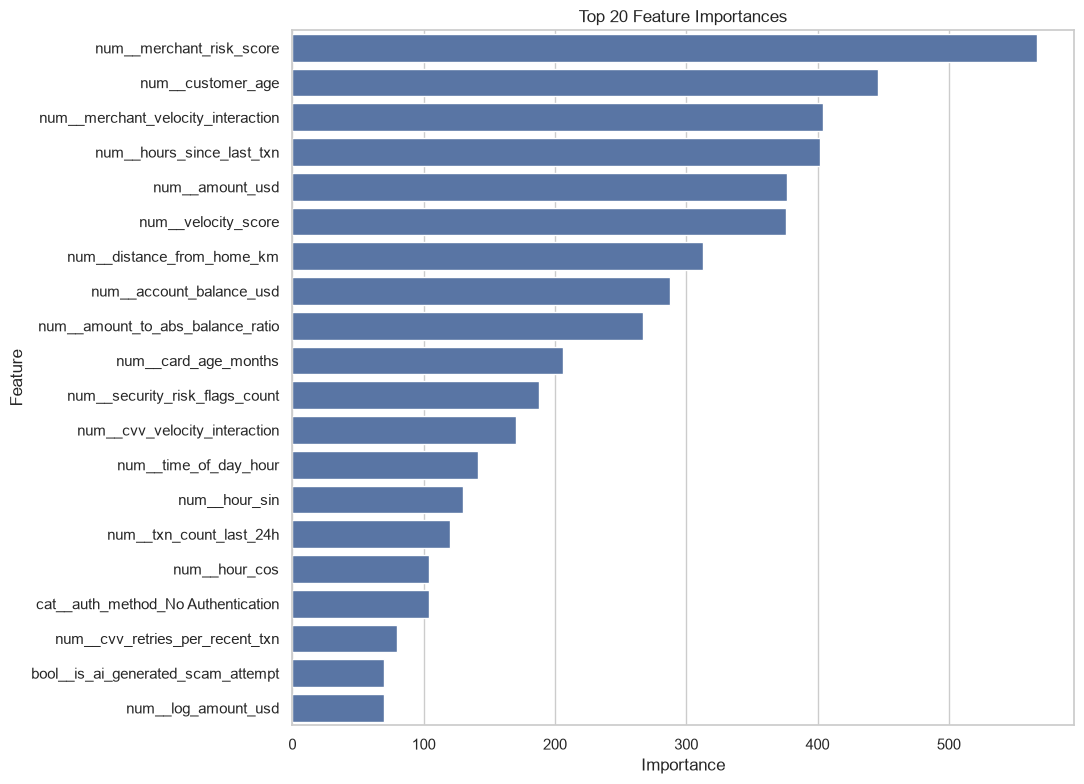

In [22]:
top_features = feature_importance_df.head(20)

plt.figure(figsize=(11, 8))

sns.barplot(
    data=top_features,
    x="importance",
    y="feature"
)

plt.title("Top 20 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()